In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tdmsLib_vObj as tdmsLib # This command imports my library of functions. The file tdmsLib.py should live in the same folder as this file.

from pathlib import Path

# Two data sets.
- The first dataset shows a less stable signal.
  - Consists of a single 30s time series.
- The second one is more stable.
  - Consists of 3 separate files.

In [2]:
# Here you define the path to your dataset 1.
path_GapData = Path.cwd() / "ExampleData" / "GapData_Janike"
fName_preamble = "Gap2_PA20260407_C4_Tween_E7L_15"
num = 15
grName = "_scattering_analog_input_"

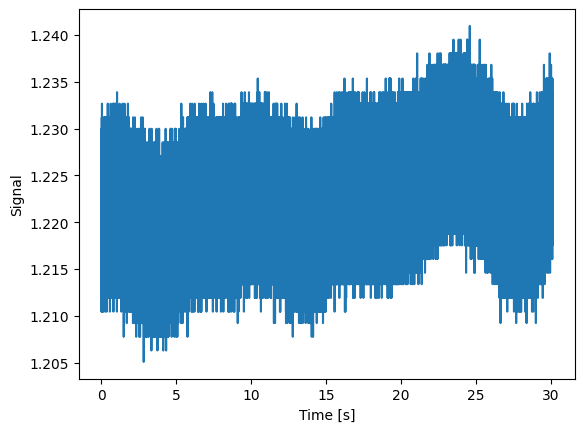

In [3]:
# readFile reads the tdms file and spits out a 1D array with the data.
tSer_Gap = tdmsLib.readFile(path_GapData, fName_preamble, num, grName)
# Display the time series
tdmsLib.dispTimeTrace(tSer_Gap)

In [4]:
# Here you define the path to your dataset 2.
path_Christmas = Path.cwd() / "ExampleData" / "StableChristmasData_Sergii" 
fName_preamble = "gap-tween-100nm-np-in gap-trapping-2V"
num_strt = 9
num_end = 10
grName = "_scattering_analog_input_"

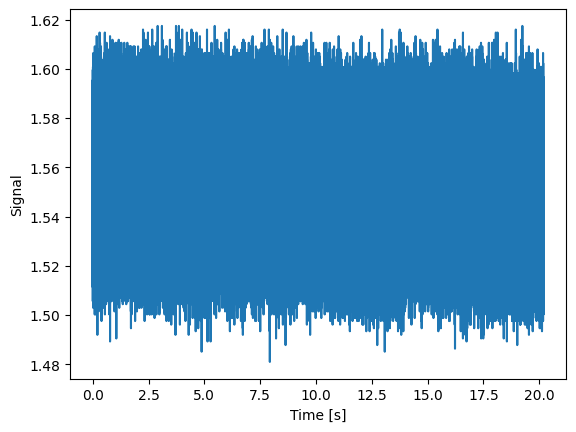

In [5]:
tSer_Stable = tdmsLib.readConsecFiles(path_Christmas, fName_preamble, grName, num_strt, num_end)
# Display the time series
tdmsLib.dispTimeTrace(tSer_Stable)

# Calculation of Allan Variance
Allan variance is given by the following formula:

 - $Var_{Allan}(\delta) = \dfrac{1}{2} \langle \bar{x}_{i+1} - \bar{x}_{i}\rangle$
where $\bar{x}_i = (x_{i\delta+1}+\dots+x_{i\delta+\delta})\Big/ \delta$

In [6]:
# An element of the blockSizes array gives the number of data points that will be in each chunk of the "blocked" array.
blockSizes = np.array([1,2,5,10,20,50,100,200,500,1e3,2e3,5e3, 1e4,2e4,5e4,1e5,2e5])

#varArr stores the variance of each array after it's been "blocked" into the appropriate block sizes.
varAllanArr_Gap = np.zeros(len(blockSizes))
varAllanArr_Gap_delta = np.zeros(len(blockSizes))
varAllanArr_Stable = np.zeros(len(blockSizes))
varAllanArr_Stable_delta = np.zeros(len(blockSizes))

# varArr, varArr_delta are filled in.
for i in range(len(blockSizes)):
    scatBlocked, remain = tdmsLib.blockData_ave(blockSizes[i], tSer_Gap)
    varAllanArr_Gap[i], varAllanArr_Gap_delta[i] = tdmsLib.compAllanVar(scatBlocked)

    scatBlocked, remain = tdmsLib.blockData_ave(blockSizes[i], tSer_Stable)
    varAllanArr_Stable[i], varAllanArr_Stable_delta[i] = tdmsLib.compAllanVar(scatBlocked)

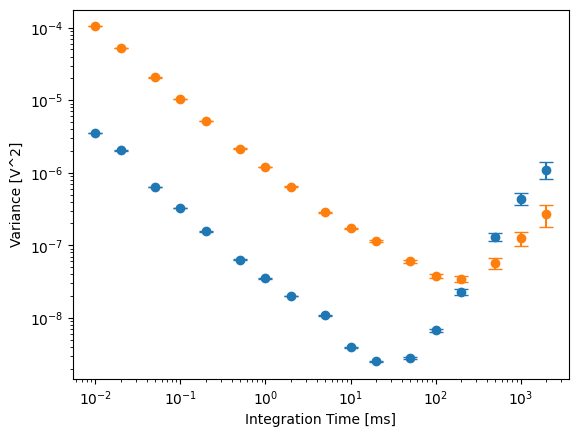

In [7]:
# Here we can plot both Allan variances.
fig, ax = plt.subplots()
ax.errorbar(blockSizes*(tSer_Gap.dT/1e-3), varAllanArr_Gap, yerr=varAllanArr_Gap_delta, fmt="o", color="tab:blue", capsize=5)
ax.errorbar(blockSizes*(tSer_Stable.dT/1e-3), varAllanArr_Stable, yerr=varAllanArr_Stable_delta, fmt="o", color="tab:orange", capsize=5)
ax.set_ylabel("Variance [V^2]")
ax.set_xlabel("Integration Time [ms]")
ax.set_yscale('log')
ax.set_xscale('log')
plt.show()

# Fitting

- Shot noise should fall at a slope of -1 on a log-log scale.
- Drift should have a slope of 2 on a log-log scale.

Below, we fit the function $f(\delta) = s\delta^{-1}+d\delta^2$ with the fitting parameters $s$ and $d$.

In [8]:
# Fit function
def allanVarFunc(tau, s, d):
    return s*(tau**(-1))+d*(tau**2)

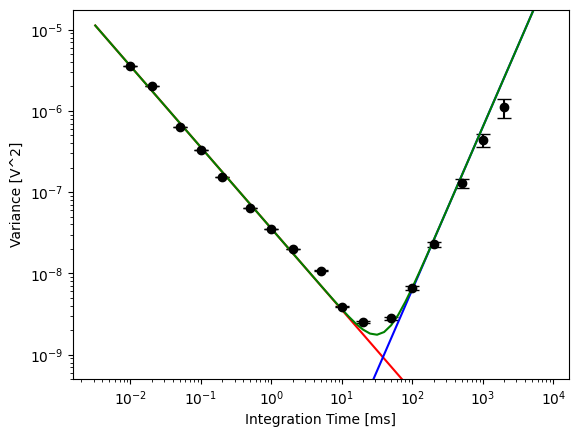

In [9]:
#Fitting routine accounting for uncertainties.

from scipy.optimize import curve_fit

popt, pcov = curve_fit(allanVarFunc, blockSizes*(tSer_Gap.dT/1e-3), varAllanArr_Gap, p0=[3e-8,1e-11], sigma=varAllanArr_Gap_delta, absolute_sigma=True)

# Generate the points for each individual exponent as well as the full fit.
xPnts = 10**(np.arange(-2.5,4,0.1))
yPnts_shot = popt[0]*(xPnts**(-1))
yPnts_drift = popt[1]*(xPnts**(2))
yPnts_fit = allanVarFunc(xPnts, popt[0], popt[1])

# Plotting
fig, ax = plt.subplots()
ax.errorbar(blockSizes*1e-2, varAllanArr_Gap, yerr=varAllanArr_Gap_delta, fmt="o", color="black", capsize=5)
ax.plot(xPnts,yPnts_shot, color="red")
ax.plot(xPnts,yPnts_drift, color="blue")
ax.plot(xPnts,yPnts_fit, color="green")
ax.set_ylabel("Variance [V^2]")
ax.set_xlabel("Integration Time [ms]")
ax.set_yscale('log')
ax.set_xscale('log')
# Set y-axis limits
ax.set_ylim(np.min(varAllanArr_Gap)/5,np.max(varAllanArr_Gap)*5)

plt.show()

In [10]:
# Saving the results in a csv to graph later in whatever graphing software you like.
np.savetxt('AllanVar.csv', np.array(list(zip(blockSizes*1e-2, varAllanArr_Gap, varAllanArr_Gap_delta))), delimiter=',', header="Integration Time [ms] | Allan Var. | Allan Var. Delta")